# Tutorial 3 — Gaia BH3: the astro-spectroscopic (joint) solution

Gaia BH3 is a 33 M☉ dormant black hole with a metal-poor giant companion (Panuzzo
et al. 2024, A&A 686, L2). It was found in pre-release Gaia astrometry, and it is one
of the three orbit sources of the DR4 pre-release. Its orbit is large (27 mas) but
long: P ≈ 11.5 yr, while the DR4 astrometry spans 5.1 yr, less than half of the
orbit. Gaia's RVS spectrometer also measured 17 radial velocities (RVs) of the
giant. This tutorial fits both data sets together: the **astro-spectroscopic**
solution. The astrometry gives the orbit on the sky and the inclination; the RVs
give the velocity amplitude; together they give the mass of the black hole and a
test of the dark-companion assumption.

**What you will do**

1. Fit the single-star model to the DR4 astrometry and reproduce ESA's numbers.
2. Profile the astrometric score over the period and see the ridge it leaves.
3. Download the Gaia RVS epoch radial velocities of BH3 from VizieR.
4. Write the RV model and its three-column design matrix.
5. Define the joint marginal likelihood and search the shared shape (P, e, τ).
6. Solve both channels, list all parameters, and derive the black-hole mass.
7. Appendix: sample the shape with emcee.

**Reference values.** ESA fitted the same pre-release astrometry with `kepmodel`
(notebook in `esa/gaia-bhthree`, branch `gaia-dr4-prerelease`): P = 4183.7 ± 72 d,
e = 0.7278, i = 110.5°, ω = 78.2°, Ω = 136.4°, ϖ = 1.660 mas, a₀ = 16.3 au. Panuzzo
et al. (2024), astrometry + RVs: P = 4253.1 ± 98.5 d, e = 0.7291 ± 0.0048,
ϖ = 1.6933 ± 0.0068 mas, m₁ = 0.76 ± 0.05 M☉, M_BH = 32.70 ± 0.82 M☉.

**Units and conventions**

- As in tutorials 1 and 2. RVs in km/s; RV epochs are Julian dates (TCB) in the
  VizieR table.
- The RV model is $v(t) = \gamma + K[\cos(\nu + \omega) + e\cos\omega]$ with $\omega$
  the argument of periastron of the **primary** (the visible star). The
  Thiele–Innes constants describe the photocentre, which is the primary for a dark
  companion, so both channels share the same $\omega$.
- `rv_design_matrix` takes the period in **years**; `ti_design_matrix` takes a
  frequency in cycles per **day**. Both take the same $\tau$ and reference epoch.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import minimize
from astropy.table import Table

from orblet.constants import MJD_J2010_TCB, MJD_J2017_5_TCB, DAYS_PER_KEPLER_YEAR
from orblet import (resolve_epochs_mjd, fit_astrometric_5param, ti_design_matrix, linear_solve_ti,
                    rv_design_matrix, linear_solve_rv, recover_K, recover_omega, ti_to_kepler,
                    prepare_rv_for_orbit)
from orblet.model import kepler_xy_orbit, rv_curve
from orblet.interpret.astrometric_upper_limit import a1sini_au, a_phot_au, mass_function_au
from orblet.interpret.companion_mass import companion_mass_from_rv_posterior
from orblet.interpret.flux_ratio import MeasuredSinI

from dr4_prerelease import (download_prerelease, read_prerelease, explode_transits,
                            matrix_markdown, params_markdown, source_id_of)

rng = np.random.default_rng(3)
EPOCH_REF = MJD_J2017_5_TCB
DATA_DIR = Path("_data")

table = read_prerelease(download_prerelease(DATA_DIR))
astro = explode_transits(table, source_id_of("Gaia BH3"))
t_ast = resolve_epochs_mjd(astro)
psi, pf, w, sig = (astro[k] for k in ("scan_angle", "parallax_factor_al", "centroid_pos", "centroid_pos_err"))
print(f"astrometry: {astro['n_transits']} transits -> {w.size} CCD data, "
      f"{(t_ast.max() - t_ast.min()) / DAYS_PER_KEPLER_YEAR:.2f} yr, median error {np.median(sig):.3f} mas, "
      f"excess noise {astro['excess_noise_mas']:.2f} mas")

astrometry: 77 transits -> 558 CCD data, 5.10 yr, median error 0.085 mas, excess noise 6.58 mas


## 1. The single-star fit, and ESA's numbers

ESA's BH3 notebook fits the same five parameters to the same CCD data, with the same
quality cut and no excess noise. The numbers must agree digit for digit. They do.
Then look at $\chi^2/\mathrm{dof}$ and at the residuals.

**Single-star solution of Gaia BH3**

| parameter | value | sigma | ESA (same data) | diff / sigma |
|---|---:|---:|---:|---:|
| dra* (mas) | 0.71000 | 0.00506 | 0.71001 | -0.00 |
| ddec (mas) | 0.26549 | 0.00452 | 0.26549 | -0.00 |
| pmra* (mas/yr) | -30.94602 | 0.00362 | -30.94602 | -0.00 |
| pmdec (mas/yr) | -148.54974 | 0.00281 | -148.54974 | -0.00 |
| plx (mas) | 0.98329 | 0.00623 | 0.98329 | 0.00 |

chi2 / dof = 6653   residual RMS = 6.63 mas


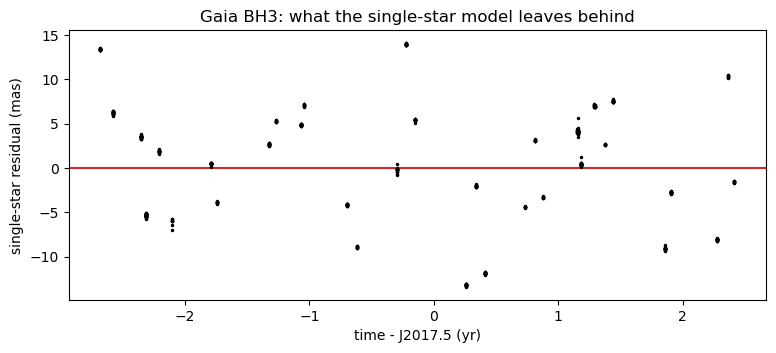

In [2]:
sol5 = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF)
PARAMS5 = ["dra* (mas)", "ddec (mas)", "pmra* (mas/yr)", "pmdec (mas/yr)", "plx (mas)"]
ESA5 = [0.71001, 0.26549, -30.94602, -148.54974, 0.98329]    # ESA BH3 pre-release notebook, single-star fit
display(params_markdown(PARAMS5, sol5.params, np.sqrt(np.diag(sol5.cov)), reference=ESA5,
                        ref_label="ESA (same data)", fmt=".5f", caption="Single-star solution of Gaia BH3"))
print(f"chi2 / dof = {sol5.chi2_per_dof:.0f}   residual RMS = {sol5.rms_mas:.2f} mas")

t_yr = (t_ast - EPOCH_REF) / DAYS_PER_KEPLER_YEAR
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(t_yr, sol5.residuals, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax.axhline(0, color="C3"); ax.set_xlabel("time - J2017.5 (yr)"); ax.set_ylabel("single-star residual (mas)")
ax.set_title("Gaia BH3: what the single-star model leaves behind"); plt.show()

$\chi^2/\mathrm{dof} \approx 6600$ and residuals of ±20 mas with a clear curve:
this star is not single. The residual arc is the orbit, 27 mas across, seen under
changing scan angles. Note also the "parallax" of 0.98 mas: a wrong model gives a
wrong parallax. The orbit fit below gives 1.66 mas.

## 2. What the astrometry alone knows

The periodogram of tutorial 2 used a grid in $(e, \tau)$. That is not good enough
here: for a long, eccentric orbit the score is extremely sharp in $\tau$ (the
periastron passage is a short event), and a grid misses the ridge. Instead,
**profile** the score: at each period, optimise $(e, \tau)$ with Nelder–Mead from a
few starts and keep the best value. The second panel shows how $e$ and $a_0$ move
along the ridge.

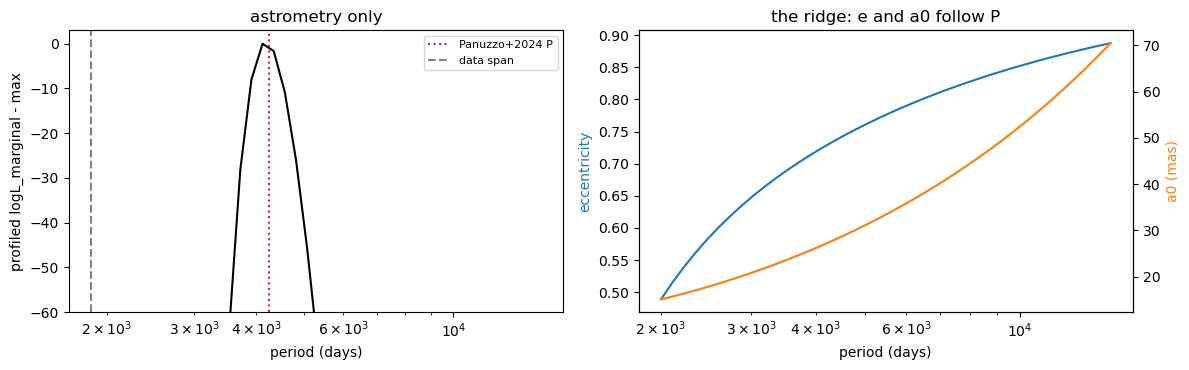

astrometry alone: best period near 4122 d


In [3]:
def solve_ast(P, e, tau):
    X = ti_design_matrix(t_ast, psi, pf, f_per_day=1.0 / P, ecc=e, tau=tau, epoch_ref_mjd=EPOCH_REF)
    return linear_solve_ti(w, sig, X), X


def profile_over_shape(P, score):
    # Best score at fixed P over (e, tau): Nelder-Mead from a small set of starts.
    best = None
    for e0 in (0.5, 0.7, 0.85):
        for tau0 in np.linspace(0.05, 0.95, 4):
            f = lambda x: -score(P, x[0], x[1]) if (0.0 <= x[0] < 0.95 and 0.0 <= x[1] < 1.0) else 1e12
            r = minimize(f, [e0, tau0], method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-2))
            if best is None or r.fun < best.fun:
                best = r
    return -best.fun, best.x[0], best.x[1]


periods = np.geomspace(2000.0, 15000.0, 40)
prof_ast = np.array([profile_over_shape(P, lambda P, e, tau: solve_ast(P, e, tau)[0].logL_marginal)
                     for P in periods])                     # columns: logL, e, tau
a0_ridge = np.array([ti_to_kepler({k: solve_ast(P, e, tau)[0].beta[[i]] for k, i in
                                   [("A_mas", 0), ("B_mas", 1), ("F_mas", 2), ("G_mas", 3), ("plx_mas", 8)]})["a_phot_mas"][0]
                     for P, (_, e, tau) in zip(periods, prof_ast)])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(periods, prof_ast[:, 0] - prof_ast[:, 0].max(), color="k")
ax[0].axvline(4253.0, color="C3", ls=":", label="Panuzzo+2024 P")
ax[0].axvline(t_ast.max() - t_ast.min(), color="0.5", ls="--", label="data span")
ax[0].set_xscale("log"); ax[0].set_ylim(-60, 3); ax[0].legend(fontsize=8)
ax[0].set_xlabel("period (days)"); ax[0].set_ylabel("profiled logL_marginal - max"); ax[0].set_title("astrometry only")
ax[1].plot(periods, prof_ast[:, 1], color="C0", label="e"); ax[1].set_ylabel("eccentricity", color="C0")
ax2 = ax[1].twinx(); ax2.plot(periods, a0_ridge, color="C1", label="a0"); ax2.set_ylabel("a0 (mas)", color="C1")
ax[1].set_xscale("log"); ax[1].set_xlabel("period (days)"); ax[1].set_title("the ridge: e and a0 follow P")
plt.tight_layout(); plt.show()
P_ast_best = periods[np.argmax(prof_ast[:, 0])]
print(f"astrometry alone: best period near {P_ast_best:.0f} d")

The astrometry alone does prefer a period: about 4200 d, with a width of a few
hundred days. The orbit is longer than the data, so the preference is not sharp,
and it comes with a ridge: a longer period needs a larger and more eccentric orbit
to fit the same 5-year arc (right panel). Everything the astrometry says about the
companion mass, $f_\mathrm{ast} = a_0^3/P^2$, moves along this ridge too. The radial
velocities add an independent quantity: the velocity amplitude $K$.

## 3. The radial velocities

Gaia's RVS spectrometer measured 17 epoch RVs of BH3. Panuzzo et al. (2024)
published them in their Table B.2, which VizieR serves as catalogue `J/A+A/686/L2`.
`astroquery` downloads it. The code caches the table in `_data/` as ECSV.

The RV model needs three columns: an epoch, a velocity and its error. The times are
Julian dates in TCB; `prepare_rv_for_orbit(..., time_scale="jd")` converts them to
MJD, the scale of the astrometric epochs.

**VizieR J/A+A/686/L2, table B.2: 17 epoch RVs of Gaia BH3**

| column | unit | description |
|---|---|---|
| `TransitID` | None | Unique identifier of the observation (transit_id) (G1) |
| `ObsTime` | d | Julian date (TCB) of the observation (obs_time_tcb) (G3) |
| `RV` | km / s | Radial velocity measurement (radial_velocity) (G9) |
| `e_RV` | km / s | Formal error on the radial velocity (radial_velocity_err) |

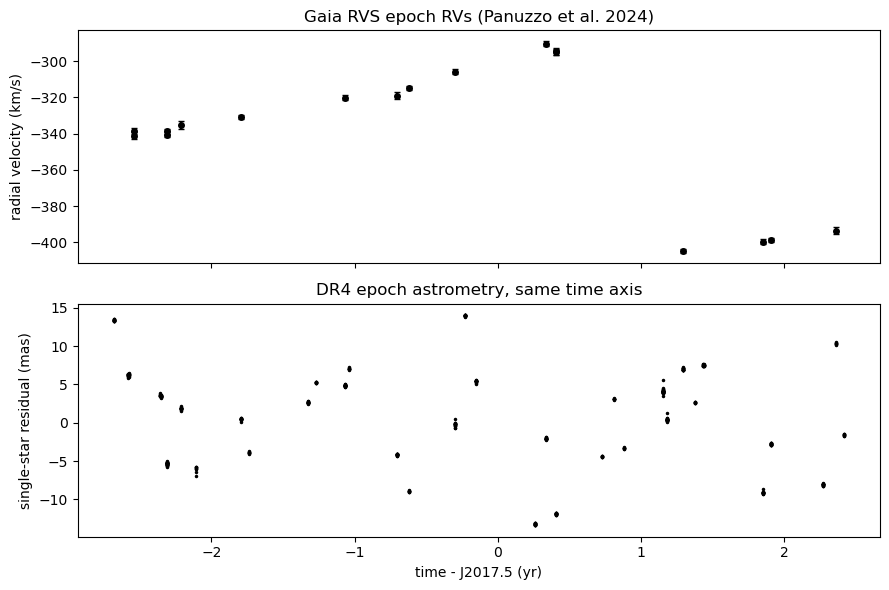

RV: 17 epochs over 4.90 yr, median error 1.43 km/s, range -404.7 to -290.3 km/s


In [4]:
rv_path = DATA_DIR / "bh3_rv_panuzzo2024_tableb2.ecsv"
if not rv_path.exists():
    from astroquery.vizier import Vizier
    cats = Vizier(row_limit=-1).get_catalogs("J/A+A/686/L2")      # row_limit=-1: all rows, not 50
    rv_table = [t for t in cats if "RV" in t.colnames][0]
    rv_table.write(rv_path, format="ascii.ecsv")
rv_table = Table.read(rv_path, format="ascii.ecsv")

lines = ["| column | unit | description |", "|---|---|---|"]
for name in rv_table.colnames:
    lines.append(f"| `{name}` | {rv_table[name].unit} | {rv_table[name].description} |")
display(Markdown(f"**VizieR J/A+A/686/L2, table B.2: {len(rv_table)} epoch RVs of Gaia BH3**\n\n" + "\n".join(lines)))

rv = prepare_rv_for_orbit({"radial_velocity": rv_table["RV"], "radial_velocity_err": rv_table["e_RV"],
                           "obs_time_rv": rv_table["ObsTime"]}, time_scale="jd")
t_rv, v, v_err = rv["epochs_mjd"], rv["rv"], rv["rv_err"]
t_rv_yr = (t_rv - EPOCH_REF) / DAYS_PER_KEPLER_YEAR

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].errorbar(t_rv_yr, v, yerr=v_err, fmt="o", ms=4, color="k", capsize=2)
ax[0].set_ylabel("radial velocity (km/s)"); ax[0].set_title("Gaia RVS epoch RVs (Panuzzo et al. 2024)")
ax[1].errorbar(t_yr, sol5.residuals, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax[1].set_ylabel("single-star residual (mas)"); ax[1].set_xlabel("time - J2017.5 (yr)")
ax[1].set_title("DR4 epoch astrometry, same time axis"); plt.tight_layout(); plt.show()
print(f"RV: {v.size} epochs over {(t_rv.max() - t_rv.min()) / DAYS_PER_KEPLER_YEAR:.2f} yr, "
      f"median error {np.median(v_err):.2f} km/s, range {v.min():.1f} to {v.max():.1f} km/s")

The RVs cover 5 years and change by 115 km/s. They catch the fast part of the
orbit near periastron, where the astrometric arc turns. The two channels cover different
parts of the same orbit; together they close it.

## 4. The RV model and its design matrix

The radial velocity of the primary on a Keplerian orbit is

$$
v(t) = \gamma + K\left[\cos(\nu + \omega) + e\cos\omega\right],
$$

with the true anomaly $\nu(t)$ from Kepler's equation (same $P$, $e$, $t_p$ as the
astrometry). Expand the cosine:

$$
v = \gamma + \underbrace{K\cos\omega}_{C}\,(\cos\nu + e) - \underbrace{K\sin\omega}_{S}\,\sin\nu .
$$

So at a fixed shape the RV model is **linear** in three amplitudes
$\boldsymbol\beta_\mathrm{RV} = (\gamma, C, S)$ with the design matrix
$X_\mathrm{RV} = [\,1,\; \cos\nu + e,\; -\sin\nu\,]$, and
$K = \sqrt{C^2 + S^2}$, $\omega = \operatorname{atan2}(S, C)$. The same trick as for
the astrometry, and the same marginal score from `linear_solve_rv`.

In [5]:
P_trial, e_trial, tau_trial = 4200.0, 0.70, 0.06     # near the published orbit
X_rv = rv_design_matrix(t_rv, period_yr=P_trial / DAYS_PER_KEPLER_YEAR, ecc=e_trial, tau=tau_trial,
                        epoch_ref_mjd=EPOCH_REF)
display(matrix_markdown(X_rv, ["1", "cos nu + e", "-sin nu"], n_rows=17, fmt=".3f",
                        caption=f"RV design matrix at P = {P_trial:.0f} d, e = {e_trial}, tau = {tau_trial}"))


def solve_rv(P, e, tau):
    X = rv_design_matrix(t_rv, period_yr=P / DAYS_PER_KEPLER_YEAR, ecc=e, tau=tau, epoch_ref_mjd=EPOCH_REF)
    return linear_solve_rv(v, v_err, X), X


sol_rv0, _ = solve_rv(P_trial, e_trial, tau_trial)
print(f"at the trial shape: gamma = {sol_rv0.beta[0]:.2f} km/s, K = {recover_K(sol_rv0.beta):.2f} km/s, "
      f"omega = {np.degrees(recover_omega(sol_rv0.beta)) % 360:.1f} deg, "
      f"chi2 / dof = {sol_rv0.chi2 / sol_rv0.dof:.2f}, logL_marginal = {sol_rv0.logL_marginal:.1f}")

**RV design matrix at P = 4200 d, e = 0.7, tau = 0.06** (shape 17 x 3)

| row | 1 | cos nu + e | -sin nu |
|---|---:|---:|---:|
| 0 | 1.000 | -0.230 | 0.368 |
| 1 | 1.000 | -0.230 | 0.368 |
| 2 | 1.000 | -0.213 | 0.407 |
| 3 | 1.000 | -0.213 | 0.407 |
| 4 | 1.000 | -0.205 | 0.425 |
| 5 | 1.000 | -0.163 | 0.505 |
| 6 | 1.000 | -0.042 | 0.671 |
| 7 | 1.000 | 0.064 | 0.772 |
| 8 | 1.000 | 0.094 | 0.796 |
| 9 | 1.000 | 0.256 | 0.896 |
| 10 | 1.000 | 1.044 | 0.939 |
| 11 | 1.000 | 1.206 | 0.863 |
| 12 | 1.000 | 1.207 | 0.862 |
| 13 | 1.000 | 0.615 | -0.996 |
| 14 | 1.000 | 0.159 | -0.841 |
| 15 | 1.000 | 0.133 | -0.824 |
| 16 | 1.000 | -0.022 | -0.692 |

at the trial shape: gamma = -357.34 km/s, K = 55.48 km/s, omega = 76.0 deg, chi2 / dof = 1.67, logL_marginal = -36.1


Seventeen rows, three columns. The second column runs from $1 + e$ at periastron to
$-1 + e$ at apastron; the third column changes sign through periastron. With only
17 epochs the shape is not well constrained by the RVs alone either. The point of
the joint fit is that each channel constrains what the other cannot.

## 5. The joint marginal likelihood

Both channels share the shape $(P, e, \tau)$. Their amplitudes are separate:
nine for the astrometry, three for the RVs. At a fixed shape the two linear solves
are independent, so the joint marginal likelihood is the **sum** of the two scores:

$$
\ln\mathcal{L}_\mathrm{joint}(P, e, \tau) =
\ln\mathcal{L}_\mathrm{marg}^\mathrm{astro}(P, e, \tau) + \ln\mathcal{L}_\mathrm{marg}^\mathrm{RV}(P, e, \tau).
$$

This is the simplest joint fit. It does not force $\omega_\mathrm{RV} = \omega_\mathrm{astro}$;
we check that afterwards, as a test of the model. The next cell profiles the RV-only
score and the joint score over the period, as section 2 did for the astrometry, and
then refines the best point in all three shape parameters with Nelder–Mead.

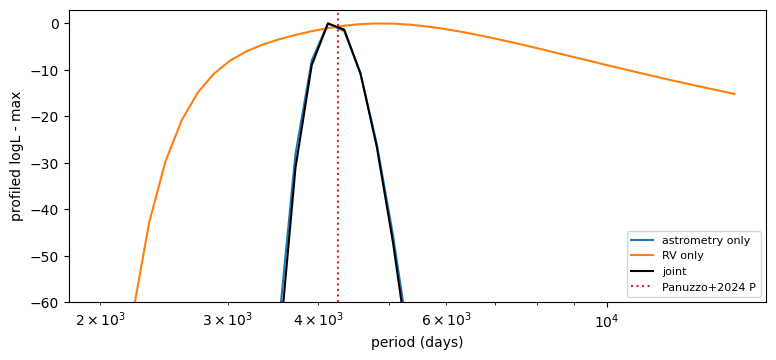

profile best: P = 4122 d, e = 0.725, tau = 0.0587
refined     : P = 4196.9 d, e = 0.7284, tau = 0.0576, tp = MJD 58178.2   (published P = 4253 +/- 99 d, e = 0.7291)


In [6]:
def joint_score(P, e, tau):
    return solve_ast(P, e, tau)[0].logL_marginal + solve_rv(P, e, tau)[0].logL_marginal


prof_rv = np.array([profile_over_shape(P, lambda P, e, tau: solve_rv(P, e, tau)[0].logL_marginal) for P in periods])
prof_joint = np.array([profile_over_shape(P, joint_score) for P in periods])

fig, ax = plt.subplots(figsize=(9, 3.8))
for prof, label, color in [(prof_ast, "astrometry only", "C0"), (prof_rv, "RV only", "C1"), (prof_joint, "joint", "k")]:
    ax.plot(periods, prof[:, 0] - prof[:, 0].max(), color=color, label=label)
ax.axvline(4253.0, color="C3", ls=":", label="Panuzzo+2024 P")
ax.set_xscale("log"); ax.set_ylim(-60, 3); ax.legend(fontsize=8)
ax.set_xlabel("period (days)"); ax.set_ylabel("profiled logL - max"); plt.show()

j0 = int(np.argmax(prof_joint[:, 0]))
res = minimize(lambda s: -joint_score(*s) if (1000 < s[0] < 20000 and 0 <= s[1] < 0.95 and 0 <= s[2] < 1) else 1e12,
               [periods[j0], prof_joint[j0, 1], prof_joint[j0, 2]], method="Nelder-Mead",
               options=dict(xatol=1e-4, fatol=1e-3))
P_ml, e_ml, tau_ml = res.x
tp_ml = tau_ml * P_ml + EPOCH_REF
print(f"profile best: P = {periods[j0]:.0f} d, e = {prof_joint[j0, 1]:.3f}, tau = {prof_joint[j0, 2]:.4f}")
print(f"refined     : P = {P_ml:.1f} d, e = {e_ml:.4f}, tau = {tau_ml:.4f}, tp = MJD {tp_ml:.1f}   "
      f"(published P = 4253 +/- 99 d, e = 0.7291)")

The RV-only profile is broad: 17 epochs over 5 years cannot fix an 11-year period
on their own. The astrometry sets the period; the joint profile follows it. What the
RVs add is not the period but the velocity scale of the orbit, $K$, and with it a
second, independent mass function. The refined joint shape agrees with the
published orbit.

## 6. Solve both channels at the best shape

Two design matrices, two linear solves. The RV amplitudes give $\gamma$, $K$ and
$\omega_\mathrm{RV}$. The astrometric amplitudes give the Thiele–Innes constants and
the five single-star parameters.

In [7]:
sol_rv, X_rv = solve_rv(P_ml, e_ml, tau_ml)
sol_ast, X_ast = solve_ast(P_ml, e_ml, tau_ml)
COLS9 = ["X cos", "X sin", "Y cos", "Y sin", "sin", "cos", "dt sin", "dt cos", "f_AL"]
PARAMS9 = ["A (mas)", "B (mas)", "F (mas)", "G (mas)",
           "dra* (mas)", "ddec (mas)", "pmra* (mas/yr)", "pmdec (mas/yr)", "plx (mas)"]
ESA9 = [2.4222, 10.5600, 20.5470, -16.9090, 3.4304, 2.5298, -28.3435, -155.1704, 1.6598]   # ESA kepmodel fit

display(matrix_markdown(X_rv, ["1", "cos nu + e", "-sin nu"], n_rows=5, fmt=".3f", caption="RV design matrix at the best shape"))
display(params_markdown(["gamma (km/s)", "C = K cos omega (km/s)", "S = K sin omega (km/s)"],
                        sol_rv.beta, np.sqrt(np.diag(sol_rv.cov)), caption="RV amplitudes"))
print(f"K = {recover_K(sol_rv.beta):.2f} km/s, omega_RV = {np.degrees(recover_omega(sol_rv.beta)) % 360:.2f} deg, "
      f"RV chi2 / dof = {sol_rv.chi2 / sol_rv.dof:.2f}")

display(matrix_markdown(X_ast, COLS9, n_rows=6, caption="Astrometric design matrix at the best shape"))
display(params_markdown(PARAMS9, sol_ast.beta, np.sqrt(np.diag(sol_ast.cov)), reference=ESA9,
                        ref_label="ESA kepmodel", caption="Astrometric amplitudes"))
print(f"astrometry chi2 / dof: single star {sol5.chi2_per_dof:.0f} -> with orbit {sol_ast.chi2 / sol_ast.dof:.2f}")

**RV design matrix at the best shape** (shape 17 x 3)

| row | 1 | cos nu + e | -sin nu |
|---|---:|---:|---:|
| 0 | 1.000 | -0.210 | 0.346 |
| 1 | 1.000 | -0.210 | 0.346 |
| 2 | 1.000 | -0.195 | 0.383 |
| 3 | 1.000 | -0.195 | 0.383 |
| 4 | 1.000 | -0.188 | 0.401 |
| ... | ... | ... | ... |

**RV amplitudes**

| parameter | value | sigma |
|---|---:|---:|
| gamma (km/s) | -357.0943 | 0.3825 |
| C = K cos omega (km/s) | 11.9032 | 0.7935 |
| S = K sin omega (km/s) | 55.4254 | 0.5060 |

K = 56.69 km/s, omega_RV = 77.88 deg, RV chi2 / dof = 1.12


**Astrometric design matrix at the best shape** (shape 558 x 9)

| row | X cos | X sin | Y cos | Y sin | sin | cos | dt sin | dt cos | f_AL |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | -0.5871 | -0.4929 | 0.5243 | 0.4402 | 0.6430 | 0.7659 | 1.4617 | 1.7411 | -0.6951 |
| 1 | -0.5871 | -0.4929 | 0.5243 | 0.4402 | 0.6430 | 0.7659 | 1.4617 | 1.7411 | -0.6951 |
| 2 | -0.5871 | -0.4929 | 0.5243 | 0.4402 | 0.6430 | 0.7659 | 1.4617 | 1.7411 | -0.6951 |
| 3 | -0.5871 | -0.4929 | 0.5243 | 0.4402 | 0.6430 | 0.7659 | 1.4617 | 1.7411 | -0.6951 |
| 4 | -0.5871 | -0.4929 | 0.5243 | 0.4402 | 0.6430 | 0.7659 | 1.4617 | 1.7411 | -0.6951 |
| 5 | -0.5871 | -0.4929 | 0.5243 | 0.4402 | 0.6430 | 0.7659 | 1.4617 | 1.7411 | -0.6951 |
| ... | ... | ... | ... | ... | ... | ... | ... | ... | ... |

**Astrometric amplitudes**

| parameter | value | sigma | ESA kepmodel | diff / sigma |
|---|---:|---:|---:|---:|
| A (mas) | 2.4252 | 0.0152 | 2.4222 | 0.19 |
| B (mas) | 10.5825 | 0.0175 | 10.5600 | 1.28 |
| F (mas) | 20.6010 | 0.0184 | 20.5470 | 2.93 |
| G (mas) | -16.9473 | 0.0213 | -16.9090 | -1.80 |
| dra* (mas) | 3.4254 | 0.0118 | 3.4304 | -0.42 |
| ddec (mas) | 2.5393 | 0.0097 | 2.5298 | 0.98 |
| pmra* (mas/yr) | -28.3344 | 0.0107 | -28.3435 | 0.85 |
| pmdec (mas/yr) | -155.1859 | 0.0087 | -155.1704 | -1.77 |
| plx (mas) | 1.6597 | 0.0064 | 1.6598 | -0.02 |

astrometry chi2 / dof: single star 6653 -> with orbit 3.03


The Thiele–Innes constants agree with ESA's fit to within a few formal sigma, and
the parallax moved from 0.98 mas (single-star fit) to 1.66 mas, ESA's value. The
astrometric $\chi^2/\mathrm{dof}$ fell from 6600 to 3. The rest is per-transit
noise: the CCDs of one transit move together, and our errors do not know that.

One more convention before the table. Along-scan astrometry fixes $(\omega, \Omega)$
only up to a simultaneous shift by 180°: both branches give the same $A, B, F, G$.
The RVs know $\omega$ of the primary, so the code below picks the branch of the
astrometric $(\omega, \Omega)$ that agrees with $\omega_\mathrm{RV}$.

## 7. All parameters

Draw amplitudes from both covariances, convert the Thiele–Innes draws to Campbell
elements, and list everything. Two consistency checks come for free:

- $\omega_\mathrm{RV}$ and $\omega_\mathrm{astro}$ must agree (one orbit, one primary).
- The projected axes must agree: the RVs give $a_1 \sin i = K P \sqrt{1 - e^2} / 2\pi$,
  the astrometry gives $a_0 \sin i$ with $a_0 = a_\mathrm{phot}/\varpi$ in au. For a
  dark companion $a_0 = a_1$, so the deficit $D = 1 - a_0 \sin i / a_1 \sin i$ must
  be zero. $D > 0$ would mean a luminous companion that pulls the photocentre
  towards the barycentre.

The shape is fixed here; the appendix adds its uncertainty.

In [8]:
N_DRAW = 4000
b_rv = rng.multivariate_normal(sol_rv.beta, sol_rv.cov, size=N_DRAW)
b_ast = rng.multivariate_normal(sol_ast.beta, sol_ast.cov, size=N_DRAW)
K = np.hypot(b_rv[:, 1], b_rv[:, 2])
omega_rv = np.degrees(np.arctan2(b_rv[:, 2], b_rv[:, 1])) % 360
kep = ti_to_kepler({"A_mas": b_ast[:, 0], "B_mas": b_ast[:, 1], "F_mas": b_ast[:, 2],
                    "G_mas": b_ast[:, 3], "plx_mas": b_ast[:, 8]})
sin_i = np.sin(kep["inc_rad"])


def fold_to_rv_branch(omega_ast_deg, Omega_deg, omega_rv_deg):
    # Along-scan astrometry fixes (omega, Omega) only up to a simultaneous 180-degree shift.
    # The RVs know omega, so pick the branch that agrees with omega_RV.
    d = (omega_ast_deg - omega_rv_deg + 180.0) % 360.0 - 180.0
    flip = np.abs(d) > 90.0
    return ((omega_ast_deg + 180.0 * flip) % 360.0, (Omega_deg + 180.0 * flip) % 360.0)


omega_ast, Omega_ast = fold_to_rv_branch(np.degrees(kep["omega_rad"]), np.degrees(kep["Omega_rad"]), omega_rv)
a1_sini = a1sini_au(K, P_ml, e_ml)                          # RV, au
a0 = a_phot_au(kep["a_phot_mas"], b_ast[:, 8])              # astrometry, au
D = 1.0 - a0 * sin_i / a1_sini

REF = {"P (d)": 4183.7, "e": 0.7278, "i (deg)": 110.5456, "omega_ast (deg)": 78.2190, "Omega (deg)": 136.3603,
       "plx (mas)": 1.6598, "a0 (au)": 16.3333, "pmra* (mas/yr)": -28.3435, "pmdec (mas/yr)": -155.1704,
       "dra* (mas)": 3.4304, "ddec (mas)": 2.5298, "tp (MJD)": 53994.575}


def quantile_table(rows, caption, ref=REF, ref_label="ESA kepmodel"):
    lines = [f"| parameter | 16 % | 50 % | 84 % | {ref_label} |", "|---|---:|---:|---:|---:|"]
    for name, arr in rows:
        r = ref.get(name); r_s = "" if r is None else f"{r:.4f}"
        if np.ndim(arr) == 0:
            lines.append(f"| {name} | | {arr:.4f} (fixed) | | {r_s} |")
        else:
            q = np.nanpercentile(arr, [16, 50, 84])
            lines.append(f"| {name} | {q[0]:.4f} | {q[1]:.4f} | {q[2]:.4f} | {r_s} |")
    return Markdown(f"**{caption}**\n\n" + "\n".join(lines))


rows = [("P (d)", P_ml), ("e", e_ml), ("tau", tau_ml), ("tp (MJD)", tp_ml),
        ("gamma (km/s)", b_rv[:, 0]), ("K (km/s)", K), ("omega_RV (deg)", omega_rv),
        ("A (mas)", b_ast[:, 0]), ("B (mas)", b_ast[:, 1]), ("F (mas)", b_ast[:, 2]), ("G (mas)", b_ast[:, 3]),
        ("a0 (mas)", kep["a_phot_mas"]), ("a0 (au)", a0), ("i (deg)", np.degrees(kep["inc_rad"])),
        ("omega_ast (deg)", omega_ast), ("Omega (deg)", Omega_ast),
        ("dra* (mas)", b_ast[:, 4]), ("ddec (mas)", b_ast[:, 5]),
        ("pmra* (mas/yr)", b_ast[:, 6]), ("pmdec (mas/yr)", b_ast[:, 7]), ("plx (mas)", b_ast[:, 8]),
        ("a1 sin i (au, RV)", a1_sini), ("a0 sin i (au, astro)", a0 * sin_i), ("deficit D", D)]
display(quantile_table(rows, "Gaia BH3: joint solution at the best shape (amplitudes drawn from their covariances)"))

**Gaia BH3: joint solution at the best shape (amplitudes drawn from their covariances)**

| parameter | 16 % | 50 % | 84 % | ESA kepmodel |
|---|---:|---:|---:|---:|
| P (d) | | 4196.8972 (fixed) | | 4183.7000 |
| e | | 0.7284 (fixed) | | 0.7278 |
| tau | | 0.0576 (fixed) | |  |
| tp (MJD) | | 58178.2238 (fixed) | | 53994.5750 |
| gamma (km/s) | -357.4798 | -357.0974 | -356.7216 |  |
| K (km/s) | 56.1982 | 56.6829 | 57.1671 |  |
| omega_RV (deg) | 77.0679 | 77.8730 | 78.7218 |  |
| A (mas) | 2.4106 | 2.4257 | 2.4401 |  |
| B (mas) | 10.5659 | 10.5822 | 10.5996 |  |
| F (mas) | 20.5829 | 20.6006 | 20.6190 |  |
| G (mas) | -16.9683 | -16.9469 | -16.9260 |  |
| a0 (mas) | 27.1583 | 27.1769 | 27.1950 |  |
| a0 (au) | 16.3118 | 16.3745 | 16.4379 | 16.3333 |
| i (deg) | 110.4954 | 110.5393 | 110.5809 | 110.5456 |
| omega_ast (deg) | 78.1787 | 78.2269 | 78.2716 | 78.2190 |
| Omega (deg) | 136.3321 | 136.3756 | 136.4190 | 136.3603 |
| dra* (mas) | 3.4140 | 3.4254 | 3.4371 | 3.4304 |
| ddec (mas) | 2.5301 | 2.5395 | 2.5489 | 2.5298 |
| pmra* (mas/yr) | -28.3448 | -28.3345 | -28.3238 | -28.3435 |
| pmdec (mas/yr) | -155.1946 | -155.1860 | -155.1773 | -155.1704 |
| plx (mas) | 1.6534 | 1.6596 | 1.6660 | 1.6598 |
| a1 sin i (au, RV) | 14.8531 | 14.9812 | 15.1092 |  |
| a0 sin i (au, astro) | 15.2751 | 15.3337 | 15.3938 |  |
| deficit D | -0.0333 | -0.0236 | -0.0137 |  |

$\omega_\mathrm{RV}$ and $\omega_\mathrm{astro}$ agree to half a degree. The
inclination, the node and the parallax agree with ESA's fit. ESA's $t_p$ differs by
one period: the periastron time is only defined modulo $P$. The deficit is
$D = -0.02 \pm 0.01$: zero within two sigma, as expected for a dark companion. A
negative $D$ has no physical meaning (a luminous companion makes $D > 0$), so the
small offset measures the limit of our error model rather than the system.

## 8. The black-hole mass

The RVs give the spectroscopic mass function

$$
f_\mathrm{spec} = \frac{(a_1 \sin i)^3\,[\mathrm{au}]}{P^2\,[\mathrm{yr}]}
= \frac{m_2^3 \sin^3 i}{(m_1 + m_2)^2} \qquad [M_\odot].
$$

The astrometry gives $\sin i$. With an external mass for the giant,
$m_1 = 0.76 \pm 0.05\ M_\odot$ (Panuzzo et al. 2024), the cubic has one positive
root $m_2$. `companion_mass_from_rv_posterior` solves it draw by draw with the
measured $\sin i$ passed as `MeasuredSinI`.

In [9]:
fm_spec = mass_function_au(a1_sini, P_ml)
mass = companion_mass_from_rv_posterior({"chains": {"fm_spec_msun": fm_spec}},
                                        primary_mass_prior=("Normal", 0.76, 0.05),
                                        sin_i=MeasuredSinI(sin_i), seed=0)
m2 = mass["mass"]["m2"]
q = np.nanpercentile(m2, [16, 50, 84])
print(f"f_spec = {np.median(fm_spec):.2f} M_sun, sin i = {np.median(sin_i):.3f}")
print(f"black-hole mass m2 = {q[1]:.1f} (+{q[2] - q[1]:.1f} / -{q[1] - q[0]:.1f}) M_sun   "
      f"(Panuzzo et al. 2024: 32.70 +/- 0.82 M_sun)")

f_spec = 25.47 M_sun, sin i = 0.936
black-hole mass m2 = 32.5 (+0.8 / -0.8) M_sun   (Panuzzo et al. 2024: 32.70 +/- 0.82 M_sun)


## Appendix: sample the shape with emcee

Section 7 fixed $(P, e, \tau)$. Sample the three shape parameters with the joint
marginal likelihood, then draw amplitudes at every sample. The period uncertainty
now propagates into every derived quantity, including the mass.

mean acceptance fraction: 0.65


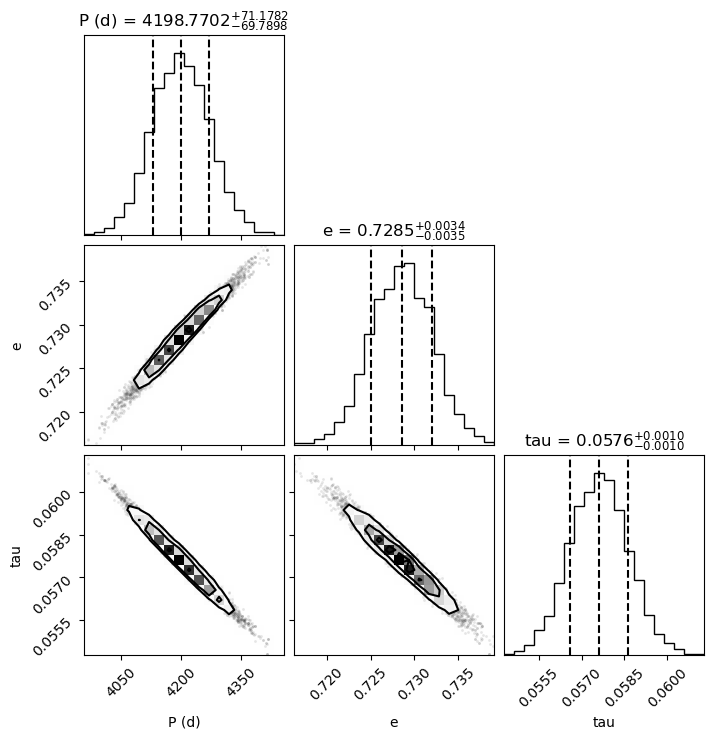

In [10]:
import emcee
import corner


def log_prob(theta):
    P, e, tau = theta
    if not (3000.0 < P < 6000.0 and 0.0 <= e < 0.95 and 0.0 <= tau < 1.0):
        return -np.inf
    return float(joint_score(P, e, tau))


n_walkers, n_dim, n_steps = 24, 3, 1500
p0 = np.array([P_ml, e_ml, tau_ml]) + np.array([5.0, 1e-3, 1e-3]) * rng.standard_normal((n_walkers, n_dim))
sampler = emcee.EnsembleSampler(n_walkers, n_dim, log_prob)
sampler.random_state = np.random.RandomState(2).get_state()
sampler.run_mcmc(p0, n_steps, progress=False)
print(f"mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.2f}")
flat = sampler.get_chain(discard=500, thin=5, flat=True)
fig = corner.corner(flat, labels=["P (d)", "e", "tau"], show_titles=True, title_fmt=".4f",
                    quantiles=[0.16, 0.5, 0.84])
plt.show()

In [11]:
b_rv_mc = np.empty((len(flat), 3)); b_ast_mc = np.empty((len(flat), 9))
for k, (P, e, tau) in enumerate(flat):
    s_rv, s_ast = solve_rv(P, e, tau)[0], solve_ast(P, e, tau)[0]
    b_rv_mc[k] = rng.multivariate_normal(s_rv.beta, s_rv.cov)
    b_ast_mc[k] = rng.multivariate_normal(s_ast.beta, s_ast.cov)
P_mc, e_mc, tau_mc = flat.T
K_mc = np.hypot(b_rv_mc[:, 1], b_rv_mc[:, 2])
omega_rv_mc = np.degrees(np.arctan2(b_rv_mc[:, 2], b_rv_mc[:, 1])) % 360
kep_mc = ti_to_kepler({"A_mas": b_ast_mc[:, 0], "B_mas": b_ast_mc[:, 1], "F_mas": b_ast_mc[:, 2],
                       "G_mas": b_ast_mc[:, 3], "plx_mas": b_ast_mc[:, 8]})
sin_i_mc = np.sin(kep_mc["inc_rad"])
omega_ast_mc, Omega_mc = fold_to_rv_branch(np.degrees(kep_mc["omega_rad"]), np.degrees(kep_mc["Omega_rad"]), omega_rv_mc)
a1_mc = a1sini_au(K_mc, P_mc, e_mc)
a0_mc = a_phot_au(kep_mc["a_phot_mas"], b_ast_mc[:, 8])
m2_mc = companion_mass_from_rv_posterior({"chains": {"fm_spec_msun": mass_function_au(a1_mc, P_mc)}},
                                         primary_mass_prior=("Normal", 0.76, 0.05),
                                         sin_i=MeasuredSinI(sin_i_mc), seed=1)["mass"]["m2"]

PAN = {"P (d)": 4253.1, "e": 0.7291, "plx (mas)": 1.6933, "m2 (M_sun)": 32.70}
rows = [("P (d)", P_mc), ("e", e_mc), ("tau", tau_mc), ("tp (MJD)", tau_mc * P_mc + EPOCH_REF),
        ("gamma (km/s)", b_rv_mc[:, 0]), ("K (km/s)", K_mc),
        ("omega_RV (deg)", omega_rv_mc),
        ("a0 (mas)", kep_mc["a_phot_mas"]), ("a0 (au)", a0_mc), ("i (deg)", np.degrees(kep_mc["inc_rad"])),
        ("omega_ast (deg)", omega_ast_mc), ("Omega (deg)", Omega_mc),
        ("pmra* (mas/yr)", b_ast_mc[:, 6]), ("pmdec (mas/yr)", b_ast_mc[:, 7]), ("plx (mas)", b_ast_mc[:, 8]),
        ("deficit D", 1.0 - a0_mc * sin_i_mc / a1_mc), ("m2 (M_sun)", m2_mc)]
display(quantile_table(rows, "Gaia BH3: full joint posterior (shape sampled, amplitudes drawn)",
                       ref=PAN, ref_label="Panuzzo+2024"))

**Gaia BH3: full joint posterior (shape sampled, amplitudes drawn)**

| parameter | 16 % | 50 % | 84 % | Panuzzo+2024 |
|---|---:|---:|---:|---:|
| P (d) | 4128.9804 | 4198.7702 | 4269.9484 | 4253.1000 |
| e | 0.7250 | 0.7285 | 0.7320 | 0.7291 |
| tau | 0.0566 | 0.0576 | 0.0586 |  |
| tp (MJD) | 58177.6417 | 58178.2713 | 58178.8406 |  |
| gamma (km/s) | -357.5057 | -357.1085 | -356.6816 |  |
| K (km/s) | 56.1882 | 56.6956 | 57.1952 |  |
| omega_RV (deg) | 77.0261 | 77.8620 | 78.7034 |  |
| a0 (mas) | 26.8306 | 27.1913 | 27.5481 |  |
| a0 (au) | 16.1497 | 16.3824 | 16.6129 |  |
| i (deg) | 110.4669 | 110.5348 | 110.6022 |  |
| omega_ast (deg) | 78.1232 | 78.2300 | 78.3372 |  |
| Omega (deg) | 136.2843 | 136.3753 | 136.4674 |  |
| pmra* (mas/yr) | -28.3833 | -28.3322 | -28.2820 |  |
| pmdec (mas/yr) | -155.2707 | -155.1886 | -155.1054 |  |
| plx (mas) | 1.6533 | 1.6598 | 1.6661 | 1.6933 |
| deficit D | -0.0341 | -0.0234 | -0.0130 |  |
| m2 (M_sun) | 31.6700 | 32.5007 | 33.3356 | 32.7000 |

With the shape sampled, the period carries an uncertainty of about 70 days
(Panuzzo et al.: 99 days), and the black-hole mass its full error. The mass agrees
with the published value. The parallax does not: 1.660 versus 1.693 mas. ESA's fit
of the same pre-release data gives our value, so the difference sits between the
pre-release astrometry and the data set of the discovery paper, not in the method.

## 9. The path on the sky and the radial velocities

The same picture as at the end of tutorial 2, with the RV panel added. The colour
is time in all three panels, so you can follow one transit from the path on the
sky to the orbit and to the RV curve. The across-scan coordinate of each transit
mean comes from the model; the two sky components of the parallax come from
`per_direction_parallax_factors`. The plot uses the maximum-likelihood solution of
section 6.

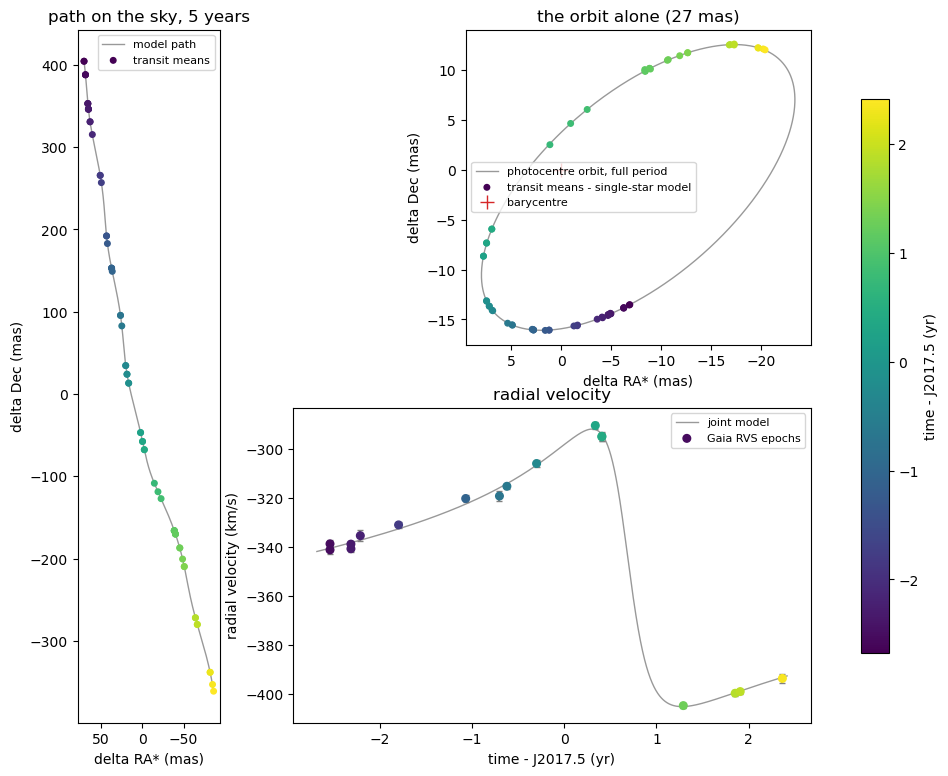

In [12]:
from orblet.parallax import per_direction_parallax_factors

beta = sol_ast.beta
P_yr = P_ml / DAYS_PER_KEPLER_YEAR


def sky_model(t, beta, orbit=True):
    # 2-D offsets (dRA*, dDec) in mas from (ra0, dec0): position + proper motion + parallax (+ orbit).
    dt = (t - EPOCH_REF) / DAYS_PER_KEPLER_YEAR
    F_ra, F_dec = per_direction_parallax_factors(t, astro["ra0_deg"], astro["dec0_deg"])
    ra = beta[4] + beta[6] * dt + beta[8] * F_ra
    dec = beta[5] + beta[7] * dt + beta[8] * F_dec
    if orbit:
        x, y = kepler_xy_orbit(t, period_yr=P_yr, ecc=e_ml, tp_mjd=tp_ml)
        ra, dec = ra + beta[1] * x + beta[3] * y, dec + beta[0] * x + beta[2] * y
    return ra, dec


resid = w - X_ast @ beta
ra_m, dec_m = sky_model(t_ast, beta)
ra_s, dec_s = sky_model(t_ast, beta, orbit=False)
uniq, inv = np.unique(astro["transit_id"], return_inverse=True)
n_per = np.bincount(inv)
ra_tr, dec_tr, t_tr = (np.bincount(inv, a) / n_per for a in
                       (ra_m + resid * np.sin(psi), dec_m + resid * np.cos(psi), t_yr))
ra_orb, dec_orb = (np.bincount(inv, a) / n_per for a in
                   (ra_m - ra_s + resid * np.sin(psi), dec_m - dec_s + resid * np.cos(psi)))

t_lo, t_hi = min(t_ast.min(), t_rv.min()), max(t_ast.max(), t_rv.max())
t_curve = np.linspace(t_lo, t_hi, 3000)
ra_c, dec_c = sky_model(t_curve, beta)
t_orb = tp_ml + np.linspace(0.0, P_ml, 600)
xo, yo = kepler_xy_orbit(t_orb, period_yr=P_yr, ecc=e_ml, tp_mjd=tp_ml)
v_curve = rv_curve(t_curve, period_yr=P_yr, ecc=e_ml, omega_rad=recover_omega(sol_rv.beta), tau=tau_ml,
                   K_kms=recover_K(sol_rv.beta), offset_kms=sol_rv.beta[0], epoch_ref_mjd=EPOCH_REF)
cmap, vmin, vmax = "viridis", (t_lo - EPOCH_REF) / DAYS_PER_KEPLER_YEAR, (t_hi - EPOCH_REF) / DAYS_PER_KEPLER_YEAR

# The path runs north-south: a tall panel on the left; orbit and RVs stacked on the right.
fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.4])
ax = [fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])]
ax[0].plot(ra_c, dec_c, color="0.6", lw=1, label="model path")
sc = ax[0].scatter(ra_tr, dec_tr, c=t_tr, cmap=cmap, vmin=vmin, vmax=vmax, s=16, zorder=3, label="transit means")
ax[0].set_title("path on the sky, 5 years")
ax[1].plot(beta[1] * xo + beta[3] * yo, beta[0] * xo + beta[2] * yo, color="0.6", lw=1, label="photocentre orbit, full period")
ax[1].scatter(ra_orb, dec_orb, c=t_tr, cmap=cmap, vmin=vmin, vmax=vmax, s=16, zorder=3, label="transit means - single-star model")
ax[1].plot(0, 0, "+", color="C3", ms=10, label="barycentre")
ax[1].set_title("the orbit alone (27 mas)")
for a in ax[:2]:
    a.set_xlabel("delta RA* (mas)"); a.set_ylabel("delta Dec (mas)"); a.invert_xaxis(); a.set_aspect("equal"); a.legend(fontsize=8)
ax[2].plot((t_curve - EPOCH_REF) / DAYS_PER_KEPLER_YEAR, v_curve, color="0.6", lw=1, label="joint model")
ax[2].errorbar(t_rv_yr, v, yerr=v_err, fmt="none", ecolor="0.5", capsize=2, zorder=2)
ax[2].scatter(t_rv_yr, v, c=t_rv_yr, cmap=cmap, vmin=vmin, vmax=vmax, s=30, zorder=3, label="Gaia RVS epochs")
ax[2].set_xlabel("time - J2017.5 (yr)"); ax[2].set_ylabel("radial velocity (km/s)"); ax[2].set_title("radial velocity")
ax[2].legend(fontsize=8)
fig.colorbar(sc, ax=ax, label="time - J2017.5 (yr)", shrink=0.8); plt.show()

Left: the giant moves 790 mas in five years; the parallax (1.7 mas) is too small to
see, but the orbit (27 mas) bends the path. Middle: the orbit alone, with the
full 11.5-year ellipse from the model and the 5-year arc that Gaia saw. Right: the
RVs sample the fast part near periastron (the yellow points), where the arc turns
in the middle panel. Neither channel alone covers the orbit; the joint fit does.

## Summary

- The same shape $(P, e, \tau)$ drives two linear models: nine astrometric
  amplitudes and three RV amplitudes. The joint marginal likelihood is the sum of the
  two scores.
- When the orbit is longer than the data, the astrometry leaves a ridge in
  $(P, e, a_0)$. For a long, eccentric orbit, profile the score with an optimiser;
  a grid in $\tau$ misses the ridge.
- The RVs add the velocity amplitude $K$. The two channels test each other: $\omega$
  must agree, and the projected axes must agree ($D = 0$) for a dark companion.
- With $\sin i$ from the astrometry and $m_1$ from a stellar model, the spectroscopic
  mass function gives the companion mass: a 33 M☉ black hole.

**Exercises**

1. Remove the RVs from `joint_score` and run the emcee appendix. How wide is the
   period posterior now, and what happens to $a_0$ and $e$?
2. Add the excess noise to the astrometric errors (`add_excess_noise=True`) and
   repeat section 6. Which parameters change, and which formal errors?
3. Fit only the RVs (`solve_rv` with Nelder–Mead on its own score). Compare the
   period with the joint result.